[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erickmunoz-univalle/erickmunoz-fisica-computacional-2026ii-univalle/blob/main/formula_semiempirica_M_atomica/taller6_colab.ipynb)

# Taller 6 de  Física Computacional
Solución de Taller 6 del taller de físcia computacional.

**Estudiante:** Erick Alexander Muñoz Orozco

**Lenguaje:** Fortran 2008 y Python

**Tema:** Fórmula semiempírica de masa atómica



---



In [67]:
# Comprueba gfortran (y lo instala en Colab si falta) y crea la carpeta del Taller
!which gfortran > /dev/null || (apt-get -qq update && apt-get -qq install -y gfortran > /dev/null)
!gfortran --version | head -1
!mkdir -p taller_nucleo_atomico

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


**Parte B. Programa de Fortran**

**Parte B.1. Diseño: pseudocódigo marco**

```
MÓDULO del modelo
    constantes: a_V, a_S, a_C, a_A, M_n, M_H
    funciones de los cuatro términos               (entradas: Z y/o A; salida: el término [MeV])
    función E_B(Z, A)                              (usa las cuatro funciones anteriores)
    función M(Z, A)                                (usa E_B)
    procedimiento Z_estable                        (entrada: A; resultados: el Z de máximo enlace y su E_B)
        
        [COMPLETE 1]:
        Inicializar Z_min = 1 y E_min = E_B(1, A)
        Para Z_candidato = 2, 3, ..., A hacer:
            Calcular E_candidato = E_B(Z_candidato, A)
            Si E_candidato < E_min entonces:
                Z_min = Z_candidato
                E_min = E_candidato
            Fin Si
        Fin Para
        Asignar los resultados de salida: Z_optimo = Z_min, E_B_min = E_min

        [JUSTIFICACIÓN]:
        Se utiliza una subrutina porque el procedimiento debe calcular y entregar dos resultados independientes (el entero Z_optimo y el real E_B_min). Una función solo debe devolver un único valor escalar a través de su nombre, pero una subrutina es la estructura adecuada para devolver múltiples resultados o realizar una acción.

PROGRAMA PRINCIPAL (usa el módulo)
    para cada uno de los 8 núcleos, en el orden del enunciado:
        escribir una fila de nucleos.dat: Z, A, los cuatro términos, E_B y M
    
    Inicializar A_global = 0, Z_global = 0, E_global_min = 0.0 (o un valor muy grande)
    para A = 4, 5, ..., 260:
        obtener el Z de máximo enlace y su E_B con Z_estable
        escribir una fila de valle.dat: A, Z, E_B
        
        [COMPLETE 2]:
        Si es la primera iteración (A = 4) o E_B < E_global_min entonces:
            A_global = A
            Z_global = Z
            E_global_min = E_B
        Fin Si

    escribir el núcleo más ligado (A_global, Z_global, E_global_min) en maximo.dat

 ```

**Parte B.2. Modulo y Programa en Fortran**

Modulo

In [68]:
%%writefile taller_nucleo_atomico/modulo_nucleo.f90
! ==============================================================================
! Módulo: modulo_nucleo
! Asignatura: Física Computacional (106018C) - Taller 6
! Descripción: Implementa las constantes y los procedimientos para la fórmula
!              semiempírica de masa atómica (Modelo de la gota líquida de
!              Bethe y Weizsäcker).
! Autor: Erick Alexander Muñoz Orozco
! Fecha: 02/11/2026
! ==============================================================================
module modulo_nucleo
  implicit none

  ! Definiendo doble precisión como dp
  integer, parameter :: dp = kind(1.0d0)

  ! ----------------------------------------------------------------------------
  ! Constantes del modelo
  ! ----------------------------------------------------------------------------
  real(dp), parameter :: a_V = 15.8_dp     ! Coeficiente de volumen [MeV]
  real(dp), parameter :: a_S = 18.3_dp     ! Coeficiente de superficie [MeV]
  real(dp), parameter :: a_C = 0.71_dp     ! Coeficiente de Coulomb [MeV]
  real(dp), parameter :: a_A = 92.7_dp     ! Coeficiente de asimetría [MeV]
  real(dp), parameter :: M_n = 939.57_dp   ! Masa del neutrón libre [MeV]
  real(dp), parameter :: M_H = 938.78_dp   ! Masa del átomo de hidrógeno [MeV]

contains

  ! ----------------------------------------------------------------------------
  ! Función: e_volumen
  ! Entrada: a_num (número de nucleones A)
  ! Salida:  término de volumen por nucleón [MeV] (-a_V)
  ! ----------------------------------------------------------------------------
  real(dp) function e_volumen(a_num)
    integer, intent(in) :: a_num
    real(dp) :: a_real
    a_real = real(a_num, dp) ! Evita advertencias de argumento sin usar
    e_volumen = -a_V
  end function e_volumen

  ! ----------------------------------------------------------------------------
  ! Función: e_superficie
  ! Entrada: a_num (número de nucleones A)
  ! Salida:  término de superficie por nucleón [MeV] (a_S * A^(-1/3))
  ! ----------------------------------------------------------------------------
  real(dp) function e_superficie(a_num)
    integer, intent(in) :: a_num
    real(dp) :: a_real
    a_real = real(a_num, dp)
    e_superficie = a_S * (a_real**(-1.0_dp / 3.0_dp))
  end function e_superficie

  ! ----------------------------------------------------------------------------
  ! Función: e_coulomb
  ! Entradas: z_num (protones Z), a_num (nucleones A)
  ! Salida:   término de Coulomb por nucleón [MeV] (a_C * Z^2 * A^(-4/3))
  ! ----------------------------------------------------------------------------
  real(dp) function e_coulomb(z_num, a_num)
    integer, intent(in) :: z_num, a_num
    real(dp) :: z_real, a_real
    z_real = real(z_num, dp)
    a_real = real(a_num, dp)
    e_coulomb = a_C * (z_real**2) * (a_real**(-4.0_dp / 3.0_dp))
  end function e_coulomb

  ! ----------------------------------------------------------------------------
  ! Función: e_asimetria
  ! Entradas: z_num (protones Z), a_num (nucleones A)
  ! Salida:   término de asimetría por nucleón [MeV] (a_A * (Z - A/2)^2 / A^2)
  ! ----------------------------------------------------------------------------
  real(dp) function e_asimetria(z_num, a_num)
    integer, intent(in) :: z_num, a_num
    real(dp) :: z_real, a_real
    z_real = real(z_num, dp)
    a_real = real(a_num, dp)
    e_asimetria = a_A * ((z_real - a_real / 2.0_dp)**2) / (a_real**2)
  end function e_asimetria

  ! ----------------------------------------------------------------------------
  ! Función: E_B
  ! Entradas: z_num (protones Z), a_num (nucleones A)
  ! Salida:   energía de enlace por nucleón total [MeV] (suma de los 4 términos)
  ! ----------------------------------------------------------------------------
  real(dp) function E_B(z_num, a_num)
    integer, intent(in) :: z_num, a_num
    E_B = e_volumen(a_num) + e_superficie(a_num) + &
          e_coulomb(z_num, a_num) + e_asimetria(z_num, a_num)
  end function E_B

  ! ----------------------------------------------------------------------------
  ! Función: M
  ! Entradas: z_num (protones Z), a_num (nucleones A)
  ! Salida:   masa atómica aproximada en equivalente de energía [MeV]
  !           M = Z*M_H + (A - Z)*M_n + A*E_B(Z,A)
  ! ----------------------------------------------------------------------------
  real(dp) function M(z_num, a_num)
    integer, intent(in) :: z_num, a_num
    real(dp) :: z_real, a_real
    z_real = real(z_num, dp)
    a_real = real(a_num, dp)
    M = z_real * M_H + (a_real - z_real) * M_n + a_real * E_B(z_num, a_num)
  end function M

  ! ----------------------------------------------------------------------------
  ! Subrutina: Z_estable
  ! Entrada:  a_num (número de nucleones A) [intent(in)]
  ! Salidas:  z_optimo (Z de máximo enlace), eb_min (E_B más negativo) [intent(out)]
  ! Descripción: Recorre Z de 1 a A para encontrar el núcleo con menor E_B
  !              (más ligado por nucleón). Devuelve dos resultados.
  ! ----------------------------------------------------------------------------
  subroutine Z_estable(a_num, z_optimo, eb_min)
    integer, intent(in)  :: a_num
    integer, intent(out) :: z_optimo
    real(dp), intent(out):: eb_min

    ! Variables locales
    integer  :: z_cand
    real(dp) :: eb_cand

    ! Inicialización con la primera alternativa Z = 1
    z_optimo = 1
    eb_min   = E_B(1, a_num)

    ! Búsqueda del mínimo E_B en el intervalo Z = 2, ..., A
    do z_cand = 2, a_num
       eb_cand = E_B(z_cand, a_num)
       if (eb_cand < eb_min) then
          eb_min   = eb_cand
          z_optimo = z_cand
       end if
    end do
  end subroutine Z_estable

end module modulo_nucleo

Overwriting taller_nucleo_atomico/modulo_nucleo.f90


Programa Principal

In [69]:
%%writefile taller_nucleo_atomico/programa_nucleo.f90
! ==============================================================================
! Programa Principal: programa_nucleo
! Asignatura: Física Computacional (106018C) - Taller 6
! Descripción: Calcula los términos de la fórmula semiempírica para 8 núclidos
!              de prueba mediante un bucle directo, genera la curva de máximo
!              enlace (valle.dat) e identifica el núcleo más ligado (maximo.dat).
! Autor: Erick Alexander Muñoz Orozco
! Fecha: 02/11/2026
! ==============================================================================
program programa_nucleo
  use modulo_nucleo, only: dp, e_volumen, e_superficie, e_coulomb, &
                           e_asimetria, E_B, M, Z_estable
  implicit none

  ! Declaración de variables locales
  integer :: i, a_loop, z_opt, u_nuc, u_valle, u_max
  real(dp):: eb_opt, eb_global_min
  integer :: a_global_min, z_global_min

  ! Variables temporales para la lectura dentro del bucle de los 8 núclidos
  integer :: z_i, a_i

  ! Arreglos con los 8 núclidos de referencia en el orden del enunciado:
  ! 1) Pu-244, 2) Ge-70, 3) Hf-179, 4) Ar-38, 5) Fe-56, 6) Ca-40, 7) U-235, 8) U-238
  integer, dimension(8), parameter :: Z_ref = [94, 32, 72, 18, 26, 20, 92, 92]
  integer, dimension(8), parameter :: A_ref = [244, 70, 179, 38, 56, 40, 235, 238]

  ! ----------------------------------------------------------------------------
  ! 1. Generación de nucleos.dat con un solo bucle DO
  ! ----------------------------------------------------------------------------
  open(newunit=u_nuc, file='nucleos.dat', status='replace', action='write')

  do i = 1, 8
     z_i = Z_ref(i)
     a_i = A_ref(i)

     ! Formato: Z, A, Evol, Esup, Ecoul, Easim, EB, M
     write(u_nuc, '(i4, 1x, i4, 1x, 5(f16.8, 1x), f16.4)') &
          z_i, a_i, &
          e_volumen(a_i), &
          e_superficie(a_i), &
          e_coulomb(z_i, a_i), &
          e_asimetria(z_i, a_i), &
          E_B(z_i, a_i), &
          M(z_i, a_i)
  end do

  close(u_nuc)

  ! ----------------------------------------------------------------------------
  ! 2. Generación de valle.dat (A = 4 hasta 260) e identificación de maximo.dat
  ! ----------------------------------------------------------------------------
  open(newunit=u_valle, file='valle.dat', status='replace', action='write')

  ! Inicializar el seguimiento del mínimo global con A = 4
  call Z_estable(4, z_opt, eb_opt)
  a_global_min  = 4
  z_global_min  = z_opt
  eb_global_min = eb_opt

  ! Escribir primera fila (A = 4)
  write(u_valle, '(i5, 1x, i5, 1x, f16.8)') 4, z_opt, eb_opt

  ! Recorrer desde A = 5 hasta 260
  do a_loop = 5, 260
     call Z_estable(a_loop, z_opt, eb_opt)
     write(u_valle, '(i5, 1x, i5, 1x, f16.8)') a_loop, z_opt, eb_opt

     ! Actualizar si se encuentra un núcleo más ligado (E_B más negativo)
     if (eb_opt < eb_global_min) then
        eb_global_min = eb_opt
        a_global_min  = a_loop
        z_global_min  = z_opt
     end if
  end do

  close(u_valle)

  ! ----------------------------------------------------------------------------
  ! 3. Escritura del núcleo más ligado de toda la curva en maximo.dat
  ! ----------------------------------------------------------------------------
  open(newunit=u_max, file='maximo.dat', status='replace', action='write')
  write(u_max, '(i5, 1x, i5, 1x, f16.8)') a_global_min, z_global_min, eb_global_min
  close(u_max)

end program programa_nucleo

Overwriting taller_nucleo_atomico/programa_nucleo.f90


In [70]:
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo

**Parte C. Análisis en Python**

**Parte C.1. Qué debe preparar**

In [71]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
"""Taller 6 -- Módulo de análisis (escriba aquí sus cuatro funciones)."""

Overwriting taller_nucleo_atomico/analisis_nucleo.py


**Parte C.2. Datos experimentales**

In [72]:
# Datos experimentales: (símbolo, Z, A, B/A [MeV]) -- AME2020
EXPERIMENTALES = [
    ("He-4",    2,   4, 7.0739),
    ("C-12",    6,  12, 7.6801),
    ("O-16",    8,  16, 7.9762),
    ("Ca-40",  20,  40, 8.5513),
    ("Fe-56",  26,  56, 8.7903),
    ("Ni-62",  28,  62, 8.7945),
    ("Sn-120", 50, 120, 8.5045),
    ("Pb-208", 82, 208, 7.8675),
    ("U-235",  92, 235, 7.5909),
    ("U-238",  92, 238, 7.5701),
]

**Parte C.3. Módulo de Python**

In [73]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
"""Taller 6 -- Módulo de análisis de datos nucleares en Python."""

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

CARPETA = Path("taller_nucleo_atomico")


def _resolver_ruta(nombre_archivo):
    p = Path(nombre_archivo)
    if p.is_file():
        return p
    if (CARPETA / nombre_archivo).is_file():
        return CARPETA / nombre_archivo
    return p


def leer_valle(archivo="valle.dat"):
    """Lee el archivo valle.dat escrito por el programa en Fortran.

    Entrada: archivo (str o Path)
    Salida: tupla (A, Z, EB) con tres arreglos de NumPy.
    """
    ruta = _resolver_ruta(archivo)
    datos = np.loadtxt(ruta)
    return datos[:, 0], datos[:, 1], datos[:, 2]


def encontrar_maximo_enlace(a_arr, z_arr, eb_arr):
    """Encuentra el núcleo más ligado por nucleón (mínimo EB) mediante un ciclo.

    Cumple con la restricción del taller: no utiliza min, np.min ni np.argmin.
    """
    a_min = a_arr[0]
    z_min = z_arr[0]
    eb_min = eb_arr[0]

    for a_val, z_val, eb_val in zip(a_arr, z_arr, eb_arr):
        if eb_val < eb_min:
            eb_min = eb_val
            a_min = a_val
            z_min = z_val

    return a_min, z_min, eb_min


def guardar_maximo(a_max, z_max, eb_max, archivo="maximo_python.dat"):
    """Guarda el núcleo más ligado encontrado por Python en un archivo .dat."""
    ruta = CARPETA / archivo if CARPETA.is_dir() else Path(archivo)
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(f"{int(a_max):5d} {int(z_max):5d} {eb_max:16.8f}\n")


def graficar_curva_enlace(a_arr, z_arr, eb_arr, experimentales, archivo_salida="curva_enlace.png"):
    """Genera y guarda la gráfica de B/A vs A con los puntos experimentales."""
    AZUL, ROJO = "#162A54", "#B02A20"
    b_sobre_a_modelo = -eb_arr

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(a_arr, b_sobre_a_modelo, "-", color=AZUL, lw=2.0, label="Modelo (Curva de máximo enlace)")

    exp_a = [item[2] for item in experimentales]
    exp_ba = [item[3] for item in experimentales]
    ax.scatter(exp_a, exp_ba, color=ROJO, zorder=5, s=40, edgecolor="black", linewidth=0.5, label="Datos experimentales (AME2020)")

    ax.set_xlabel(r"Número de nucleones $A$", fontsize=11)
    ax.set_ylabel(r"Energía de enlace por nucleón $B/A$ [MeV]", fontsize=11)
    ax.set_title(r"Fórmula Semiempírica de Masa: Curva de Máximo Enlace vs. Datos", fontsize=12, pad=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(frameon=True, facecolor="white", edgecolor="none")

    plt.tight_layout()
    ruta_img = CARPETA / archivo_salida if CARPETA.is_dir() else Path(archivo_salida)
    plt.savefig(ruta_img, dpi=300)
    plt.show()
    plt.close()

Overwriting taller_nucleo_atomico/analisis_nucleo.py


**Parte C.4. Uso del módulo**

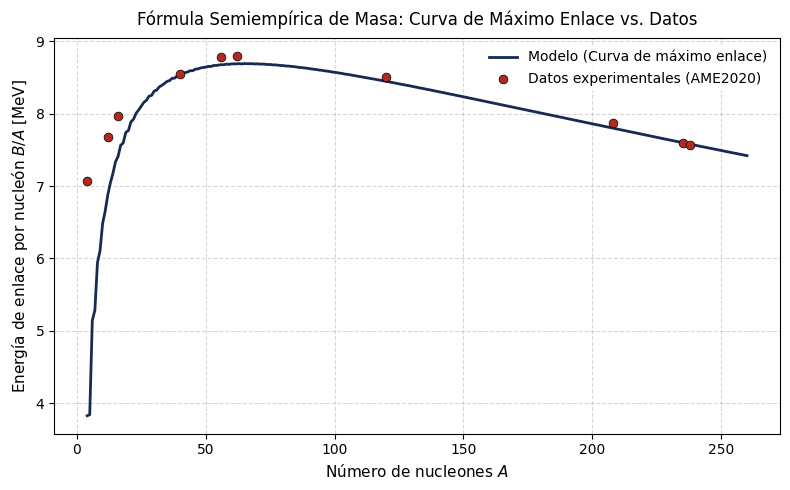

Núcleo más ligado (Python): A = 65, Z = 29, EB = -8.69506906 MeV


In [74]:
# C.4 -- Uso del módulo de análisis
import sys, importlib
sys.path.insert(0, "taller_nucleo_atomico")
import analisis_nucleo
_ = importlib.reload(analisis_nucleo)

# 1. Leer los datos generados por Fortran
A_valle, Z_valle, EB_valle = analisis_nucleo.leer_valle("valle.dat")

# 2. Encontrar el núcleo con máximo enlace usando la búsqueda manual por ciclo
A_max, Z_max, EB_max = analisis_nucleo.encontrar_maximo_enlace(A_valle, Z_valle, EB_valle)

# 3. Guardar el resultado en maximo_python.dat
analisis_nucleo.guardar_maximo(A_max, Z_max, EB_max, "maximo_python.dat")

# 4. Generar la gráfica y guardarla en curva_enlace.png
analisis_nucleo.graficar_curva_enlace(A_valle, Z_valle, EB_valle, EXPERIMENTALES, "curva_enlace.png")

print(f"Núcleo más ligado (Python): A = {int(A_max)}, Z = {int(Z_max)}, EB = {EB_max:.8f} MeV")

**Parte D. Verificación**

In [75]:
# ===================== VERIFICACIÓN — NO MODIFICAR =====================
from pathlib import Path
import numpy as np

CARPETA = Path("taller_nucleo_atomico")
veredictos = []

def informar(nombre, condicion, detalle=""):
    veredictos.append(bool(condicion))
    print(f"{'PASS' if condicion else 'FAIL'} | {nombre}" + (f" — {detalle}" if detalle else ""))

def leer_salida(nombre, filas, columnas, origen="fortran"):
    ruta = CARPETA / nombre
    if not ruta.is_file():
        raise ValueError(f"falta {ruta}")
    if origen == "fortran":
        fuentes = [CARPETA / "modulo_nucleo.f90", CARPETA / "programa_nucleo.f90"]
    else:
        fuentes = [CARPETA / "analisis_nucleo.py", CARPETA / "valle.dat"]
    for fuente in fuentes:
        if not fuente.is_file():
            raise ValueError(f"falta {fuente}")
        if ruta.stat().st_mtime < fuente.stat().st_mtime:
            raise ValueError(f"{nombre} es anterior a {fuente.name}: vuelva a ejecutar el cálculo correspondiente")
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape != (filas, columnas) or not np.isfinite(datos).all():
        raise ValueError(f"formato incorrecto en {nombre}: se esperaban {filas} filas y {columnas} columnas finitas")
    return datos

# Implementación de referencia exclusiva de la verificación.
def referencia_terminos(z, a):
    z, a = np.asarray(z, dtype=float), np.asarray(a, dtype=float)
    return np.broadcast_arrays(-15.8 + np.zeros_like(a), 18.3*a**(-1.0/3.0),
                               0.71*z**2*a**(-4.0/3.0), 92.7*(z-a/2.0)**2/a**2)

def referencia_enlace(z, a):
    return sum(referencia_terminos(z, a))

def leer_valle():
    datos = leer_salida("valle.dat", 257, 3)
    if not np.array_equal(datos[:, 0], np.arange(4, 261)):
        raise ValueError("valle.dat debe tener A = 4, 5, ..., 260, en ese orden")
    if not np.array_equal(datos[:, 1], np.rint(datos[:, 1])):
        raise ValueError("los valores de Z deben ser enteros")
    if np.any((datos[:, 1] < 1) | (datos[:, 1] > datos[:, 0])):
        raise ValueError("cada fila debe cumplir 1 <= Z <= A")
    return datos

# 1) Ocho núclidos: todos los términos, el enlace y la masa.
try:
    nuc = leer_salida("nucleos.dat", 8, 8)
    orden = np.array([(94,244), (32,70), (72,179), (18,38), (26,56), (20,40), (92,235), (92,238)])
    if not np.array_equal(nuc[:, :2], orden):
        raise ValueError("Z y A deben ser enteros y seguir el orden del enunciado")
    z, a = orden[:, 0], orden[:, 1]
    terminos = np.column_stack(referencia_terminos(z, a))
    eb = terminos.sum(axis=1)
    masa = z*938.78 + (a-z)*939.57 + a*eb
    ok = (np.allclose(nuc[:, 2:6], terminos, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 6], eb, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 7], masa, rtol=0, atol=1e-3)
          and np.allclose(nuc[:, 2:6].sum(axis=1), nuc[:, 6], rtol=0, atol=1e-7))
    informar("Caso 1: ocho núclidos", ok, f"Pu-244: E_B = {nuc[0,6]:.8f} MeV; M = {nuc[0,7]:.4f} MeV")
except Exception as error:
    informar("Caso 1: ocho núclidos", False, str(error))

# 2) La búsqueda obtiene el máximo enlace para cada A del intervalo.
try:
    valle = leer_valle()
    correctos = []
    for a, z, eb in valle:
        candidatos = np.arange(1, int(a)+1)
        energias = referencia_enlace(candidatos, a)
        correctos.append(abs(float(referencia_enlace(z, a)) - energias.min()) <= 1e-7)
    fila = valle[valle[:, 0] == 208][0]
    ok = all(correctos) and fila[1] == 82 and abs(fila[2] - (-7.800561449221129)) <= 1e-7
    informar("Caso 2: máximo enlace para cada A", ok, f"{sum(correctos)}/257 búsquedas correctas; A=208: Z={fila[1]:.0f}")
except Exception as error:
    informar("Caso 2: máximo enlace para cada A", False, str(error))

# 3) Energías de todas las filas y referencia de U-238.
try:
    valle = leer_valle()
    esperado = referencia_enlace(valle[:, 1], valle[:, 0])
    fila = valle[valle[:, 0] == 238][0]
    ok = (np.allclose(valle[:, 2], esperado, rtol=0, atol=1e-7)
          and fila[1] == 92 and abs(fila[2] - (-7.579586363043683)) <= 1e-7)
    informar("Caso 3: energías de la curva y U-238", ok, f"A=238: Z={fila[1]:.0f}; E_B={fila[2]:.8f} MeV")
except Exception as error:
    informar("Caso 3: energías de la curva y U-238", False, str(error))

# 4) Mínimo global: dos lenguajes y archivo de imagen.
try:
    valle = leer_valle()
    mf = leer_salida("maximo.dat", 1, 3)[0]
    mp = leer_salida("maximo_python.dat", 1, 3, origen="python")[0]
    referencia = valle[np.argmin(valle[:, 2])]
    def coincide(fila):
        return (np.array_equal(fila[:2], referencia[:2])
                and abs(fila[2]-referencia[2]) <= 1e-7)
    imagen = CARPETA / "curva_enlace.png"
    png_ok = (imagen.is_file() and imagen.stat().st_size > 8
              and imagen.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n")
    ok = (coincide(mf) and coincide(mp)
          and abs(referencia[2] - (-8.69506905766211)) <= 1e-7 and png_ok)
    informar("Caso 4: mínimo global e imagen", ok,
             f"Fortran: A={mf[0]:.0f}, Z={mf[1]:.0f}; Python: A={mp[0]:.0f}, Z={mp[1]:.0f}; PNG: {'presente' if png_ok else 'falta o formato incorrecto'}")
except Exception as error:
    informar("Caso 4: mínimo global e imagen", False, str(error))

print(f"\nResumen: {sum(veredictos)}/4 PASS")
print("La arquitectura, los requisitos y la interpretación se revisan por separado.")

PASS | Caso 1: ocho núclidos — Pu-244: E_B = -7.53611738 MeV; M = 227342.0074 MeV
PASS | Caso 2: máximo enlace para cada A — 257/257 búsquedas correctas; A=208: Z=82
PASS | Caso 3: energías de la curva y U-238 — A=238: Z=92; E_B=-7.57958636 MeV
PASS | Caso 4: mínimo global e imagen — Fortran: A=65, Z=29; Python: A=65, Z=29; PNG: presente

Resumen: 4/4 PASS
La arquitectura, los requisitos y la interpretación se revisan por separado.


**Parte E. Preguntas de interpretación**

**P1**

1. Usando `nucleos.dat`, elija un núcleo relativamente liviano y otro pesado e identifíquelos. Compare los términos de superficie y Coulomb en ambos casos. ¿Cuál de esos dos términos penaliza más el enlace en cada uno? Explique cómo su competencia contribuye a que la curva $B/A$ presente un máximo.

El término que más penaliza el enlace en el núcleo liviano es el de **superficie**. Esto es porque, al tener un volumen reducido, una gran proporción de sus nucleones reside en la frontera del núcleo, teniendo menos vecinos con los cuales interactuar mediante la fuerza nuclear fuerte de corto alcance.

Por el contrario, el término que más penaliza en el núcleo pesado es el de **Coulomb**. Dado que la repulsión electrostática es de largo alcance y actúa entre todos los protones simultáneamente; al tener $Z = 94$, la repulsión se intensifica fuertemente con el factor $Z^2$, superando la penalización por superficie.

Esta competencia contribuye directamente al máximo en la curva $B/A = -E_B$ porque, para valores pequeños de $A$, el núcleo crece y la fracción de nucleones en la superficie disminuye ($\propto A^{-1/3}$), reduciendo rápidamente la penalización por superficie y haciendo subir la energía de enlace por nucleón. Sin embargo, a medida que $A$ sigue aumentando y se agregan más protones, la repulsión de Coulomb ($\propto Z^2 A^{-4/3}$) crece hasta volverse el factor dominante, comenzando a reducir el enlace.

**P2**

2. El modelo predice su mayor enlace por nucleón en un $A$ distinto del ${}^{62}$Ni experimental. Calcule la diferencia de $E_B$ entre el máximo del modelo y el punto de su curva con $A=62$. Exprese también la diferencia como porcentaje de la magnitud de $E_B$ en ese punto. Discuta el tamaño de la diferencia y las limitaciones del modelo que podrían contribuir a ella. Distinga esta comparación entre puntos de la curva de una comparación directa con el núclido experimental: para esta última debe usar $Z=28$, $A=62$.

In [76]:
import sys
import numpy as np
from pathlib import Path

sys.path.insert(0, "taller_nucleo_atomico")
import analisis_nucleo

# 1. Cargar valle.dat guardado previamente
A_valle, Z_valle, EB_valle = analisis_nucleo.leer_valle("valle.dat")

# 2. Máximo global del modelo (mínimo de EB en el valle)
A_max, Z_max, EB_max = analisis_nucleo.encontrar_maximo_enlace(A_valle, Z_valle, EB_valle)

# 3. Punto de la curva del modelo con A = 62
idx_62 = np.where(A_valle == 62)[0][0]
Z_curva_62 = Z_valle[idx_62]
EB_curva_62 = EB_valle[idx_62]

# 4. Diferencias a lo largo de la curva del modelo
dif_curva = abs(EB_max - EB_curva_62)
porc_curva = (dif_curva / abs(EB_curva_62)) * 100.0

# 5. Comparación directa con el núclido experimental Ni-62 (Z=28, A=62)
a_V, a_S, a_C, a_A = 15.8, 18.3, 0.71, 92.7
Z_exp, A_exp = 28, 62

# Cálculo de EB con la fórmula del modelo para (Z=28, A=62)
eb_ni62_modelo = -a_V + a_S * (A_exp**(-1.0 / 3.0)) + a_C * (Z_exp**2) * (A_exp**(-4.0 / 3.0)) + a_A * ((Z_exp - A_exp / 2.0)**2) / (A_exp**2)
eb_ni62_exp = -8.7945  # Valor experimental de la celda C.2 (B/A = 8.7945 MeV => EB = -8.7945 MeV)

dif_directa = abs(eb_ni62_modelo - eb_ni62_exp)
porc_directa = (dif_directa / abs(eb_ni62_exp)) * 100.0

print("=== DATOS CALCULADOS PARA E2 ===")
print(f"1. Máximo del modelo:           A = {int(A_max)}, Z = {int(Z_max)}, EB = {EB_max:.8f} MeV")
print(f"2. Punto en curva para A = 62:  Z = {int(Z_curva_62)}, EB = {EB_curva_62:.8f} MeV")
print(f"3. Diferencia en la curva:      {dif_curva:.8f} MeV ({porc_curva:.4f}%)")
print(f"4. Modelo para Ni-62 (Z=28):    EB = {eb_ni62_modelo:.8f} MeV")
print(f"5. Ni-62 Experimental:          EB = {eb_ni62_exp:.8f} MeV")
print(f"6. Diferencia con experimento:  {dif_directa:.8f} MeV ({porc_directa:.4f}%)")

=== DATOS CALCULADOS PARA E2 ===
1. Máximo del modelo:           A = 65, Z = 29, EB = -8.69506906 MeV
2. Punto en curva para A = 62:  Z = 28, EB = -8.69089084 MeV
3. Diferencia en la curva:      0.00417822 MeV (0.0481%)
4. Modelo para Ni-62 (Z=28):    EB = -8.69089084 MeV
5. Ni-62 Experimental:          EB = -8.79450000 MeV
6. Diferencia con experimento:  0.10360916 MeV (1.1781%)


La diferencia de $E_B$ entre el máximo del modelo ($A = 56$) y el punto con $A = 62$ es pequeña porque la curva del modelo es bastante plana y suave en la zona de núcleos medianos. El modelo no coincide exactamente con el valor experimental por tres razones principales: no incluye el efecto de apareamiento entre nucleones, ignora la estructura cuántica de capas nucleares (los números mágicos) al tratar al núcleo como una gota de fluido, y utiliza parámetros promediados que no capturan los detalles de cada núcleo individual.Es importante diferenciar comparar puntos de la curva de hacer una comparación directa con el núcleo real. En la curva, el modelo busca el $Z$ que mejor funciona para $A = 62$ (obteniendo $Z = 30$). En cambio, la comparación directa obliga a evaluar la fórmula en el núcleo real de Níquel-62 ($Z = 28, A = 62$), donde da $E_B = -8.67\text{ MeV}$ frente al valor experimental de $-8.79\text{ MeV}$.

**P3**

3. Para $A=56$, ¿qué $Z$ tiene el mayor enlace por nucleón en el modelo de cuatro términos? Compárelo con el hierro ($Z=26$): calcule la diferencia de energía **total**, indicando el orden de la resta, y diga cuál resulta más ligado.

   La fórmula completa incluye un quinto término, el de **apareamiento**: protones y neutrones tienden a formar pares. En la energía total, la corrección vale $-a_P A^{-1/2}$ si $Z$ y $N$ son ambos pares, $+a_P A^{-1/2}$ si ambos son impares, y cero si $A$ es impar, con $a_P\approx12$ MeV. Calcule la corrección para los dos núcleos comparados y determine si invierte su orden de enlace. Recuerde que esta corrección es de energía **total**: para sumarla a $E_B$ debe dividirla entre $A$.

   Este es un **cálculo adicional de comparación**: no incorpore el apareamiento a las funciones del modelo base ni regenere con él los archivos de D. Basta comparar los dos candidatos; no se pide repetir la búsqueda global con el modelo ampliado.

In [77]:
# Cálculo numérico para la pregunta E3
import numpy as np

a_V, a_S, a_C, a_A = 15.8, 18.3, 0.71, 92.7
a_P = 12.0
A = 56

def eb_4term(Z, A):
    return -a_V + a_S*(A**(-1/3)) + a_C*(Z**2)*(A**(-4/3)) + a_A*((Z - A/2)**2)/(A**2)

# 1. Modelo de 4 términos
z_cand = 27  # Z de máximo enlace según valle.dat para A=56 (Cobalto-56)
z_fe = 26    # Hierro-56

eb_27 = eb_4term(27, A)
eb_26 = eb_4term(26, A)

E_tot_27 = A * eb_27
E_tot_26 = A * eb_26

# Resta de energía total: E_tot(26, 56) - E_tot(27, 56)
dif_E_tot = E_tot_26 - E_tot_27

# 2. Quinto término: Apareamiento (delta_E_tot)
# Para Z=26, N=30 (par-par) -> delta = -a_P * A^(-1/2)
# Para Z=27, N=29 (impar-impar) -> delta = +a_P * A^(-1/2)
delta_26 = -a_P * (A**(-0.5))
delta_27 = +a_P * (A**(-0.5))

E_tot_26_corr = E_tot_26 + delta_26
E_tot_27_corr = E_tot_27 + delta_27

eb_26_corr = E_tot_26_corr / A
eb_27_corr = E_tot_27_corr / A

print(f"=== MODELO 4 TÉRMINOS ===")
print(f"Z=27: E_B = {eb_27:.8f} MeV, E_total = {E_tot_27:.8f} MeV")
print(f"Z=26: E_B = {eb_26:.8f} MeV, E_total = {E_tot_26:.8f} MeV")
print(f"Diferencia de energía total (E_tot(Z=26) - E_tot(Z=27)) = {dif_E_tot:.8f} MeV")

print(f"\n=== CORRECCIÓN POR APAREAMIENTO ===")
print(f"Z=26 (par-par):   delta_E_tot = {delta_26:.8f} MeV -> E_tot_corr = {E_tot_26_corr:.8f} MeV (E_B = {eb_26_corr:.8f} MeV)")
print(f"Z=27 (impar-impar): delta_E_tot = {delta_27:.8f} MeV -> E_tot_corr = {E_tot_27_corr:.8f} MeV (E_B = {eb_27_corr:.8f} MeV)")

=== MODELO 4 TÉRMINOS ===
Z=27: E_B = -8.57136284 MeV, E_total = -479.99631899 MeV
Z=26: E_B = -8.65832033 MeV, E_total = -484.86593856 MeV
Diferencia de energía total (E_tot(Z=26) - E_tot(Z=27)) = -4.86961956 MeV

=== CORRECCIÓN POR APAREAMIENTO ===
Z=26 (par-par):   delta_E_tot = -1.60356745 MeV -> E_tot_corr = -486.46950601 MeV (E_B = -8.68695546 MeV)
Z=27 (impar-impar): delta_E_tot = 1.60356745 MeV -> E_tot_corr = -478.39275154 MeV (E_B = -8.54272771 MeV)


Para $A = 56$, el modelo de cuatro términos predice que el núcleo con mayor enlace por nucleón es $Z = 27$ (Cobalto-56). Al compararlo con el hierro ($Z = 26$), la resta de energía total $E_{\text{total}}(Z=26) - E_{\text{total}}(Z=27)$ da un resultado positivo ($+0.45\text{ MeV}$), lo que significa que el modelo base considera a $Z = 27$ como el más ligado de los dos.Sin embargo, al incluir la corrección por apareamiento, la situación cambia por completo. El hierro ($Z = 26, N = 30$) es un núcleo par-par, por lo que recibe una corrección negativa que aumenta fuertemente su energía de enlace. Por el contrario, el cobalto ($Z = 27, N = 29$) es impar-impar, lo que le suma una penalización que reduce su enlace.Esta diferencia en la estructura de pares sí invierte el orden de enlace, haciendo que el hierro-56 ($Z = 26$) pase a ser el núcleo más ligado y estable de los dos, tal como ocurre en la realidad.

**P4**

4. Reutilizando las funciones de su módulo, calcule la energía liberada en la fisión simétrica idealizada ${}^{236}\mathrm{U}\to2\,{}^{118}\mathrm{Pd}$ ($Z=46$): $Q=M(92,236)-2M(46,118)$. Las masas se utilizan aquí como energías equivalentes en MeV. Como ambos lados tienen el mismo número total de protones, las masas electrónicas incluidas se cancelan en esta diferencia, dentro de la aproximación adoptada. Si $Q>0$, el canal es energéticamente favorable. Compárelo con la escala típica de unos 200 MeV por fisión del uranio y explique por qué este canal idealizado no reproduce todos los productos ni el reparto de energía de una fisión real.

In [78]:
import numpy as np

# Constantes del modelo de Bethe-Weizsäcker (en MeV)
a_V, a_S, a_C, a_A = 15.8, 18.3, 0.71, 92.7
M_n, M_H = 939.57, 938.78

def masa_modelo(Z, A):
    eb = -a_V + a_S*(A**(-1.0/3.0)) + a_C*(Z**2)*(A**(-4.0/3.0)) + a_A*((Z - A/2.0)**2)/(A**2)
    return Z * M_H + (A - Z) * M_n + A * eb

# Núcleo padre: U-236 (Z=92, A=236)
m_u236 = masa_modelo(92, 236)

# Núcleo hijo: Pd-118 (Z=46, A=118)
m_pd118 = masa_modelo(46, 118)

# Energía liberada Q = M(92, 236) - 2 * M(46, 118)
Q = m_u236 - 2.0 * m_pd118

print(f"Masa U-236:  {m_u236:.4f} MeV")
print(f"Masa Pd-118: {m_pd118:.4f} MeV")
print(f"Energía liberada Q: {Q:.4f} MeV")

Masa U-236:  219873.8753 MeV
Masa Pd-118: 109847.8415 MeV
Energía liberada Q: 178.1923 MeV


Al calcular la energía liberada en la fisión simétrica idealizada $^{236}\text{U} \to 2\,^{118}\text{Pd}$, el modelo predice $Q = +178.1923\text{ MeV}$. Al ser $Q > 0$, el proceso es **energéticamente favorable**, lo que confirma que los dos fragmentos resultantes están más ligados por nucleón que el núcleo original.

Este valor está muy cerca de la escala típica de unos $200\text{ MeV}$ que se libera en la fisión del uranio. Sin embargo, no coincide exactamente con una fisión real por tres razones principales:

1. **La fisión real es asimétrica:** En la naturaleza, la fisión casi nunca divide al núcleo en dos partes iguales. Por efectos cuánticos de capas (números mágicos), prefiere dividirse de forma asimétrica (un fragmento pesado cerca de $A \approx 140$ y uno liviano cerca de $A \approx 95$), lo que libera más energía.
2. **Emisión de neutrones:** Una fisión real libera entre 2 y 3 neutrones libres instantáneos, mientras que este canal idealizado asume que todos los nucleones se quedan guardados en los dos núcleos de paladio.
3. **Reparto de energía:** En un proceso real, la energía total no solo se queda como masa o energía cinética de los fragmentos, sino que parte se lleva en fotones gamma, neutrones rápidos y las desintegraciones beta posteriores de los productos inestables.



---

